<a href="https://colab.research.google.com/github/dudekulapeeravali2537sse-bot/ITA0616/blob/main/EXP_18.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Features:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Target Classes:
['setosa' 'versicolor' 'virginica']

Dataset Shape: (150, 4)

Perceptron Classification Results
---------------------------------
Accuracy: 86.66666666666667 %

Confusion Matrix:
[[10  0  0]
 [ 0  7  3]
 [ 0  1  9]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.88      0.70      0.78        10
   virginica       0.75      0.90      0.82        10

    accuracy                           0.87        30
   macro avg       0.88      0.87      0.87        30
weighted avg       0.88      0.87      0.87        30



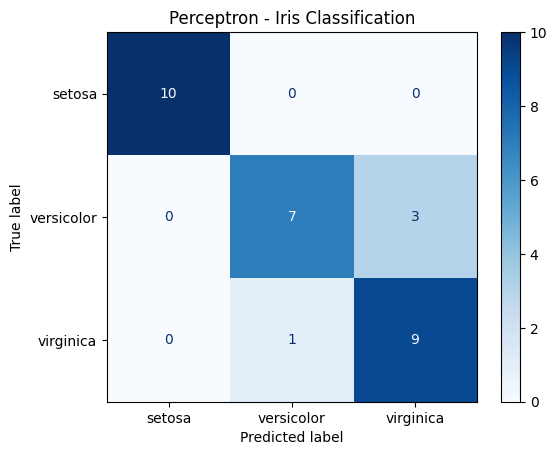


New Flower Prediction:
Predicted Species: setosa

Predictions saved to perceptron_iris_predictions.csv


In [1]:

# Perceptron-Based IRIS Classification

# Step 1: Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Step 2: Load Iris dataset
iris = load_iris()

X = iris.data
y = iris.target

print("Dataset Features:")
print(iris.feature_names)

print("\nTarget Classes:")
print(iris.target_names)

print("\nDataset Shape:", X.shape)

# Step 3: Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Step 4: Standardize the features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Step 5: Create and train Perceptron model
model = Perceptron(
    max_iter=1000,
    eta0=0.1,
    random_state=42,
    tol=1e-3
)

model.fit(X_train, y_train)

# Step 6: Make predictions
y_pred = model.predict(X_test)

# Step 7: Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

print("\nPerceptron Classification Results")
print("---------------------------------")
print("Accuracy:", accuracy * 100, "%")

print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

# Step 8: Display confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

display.plot(cmap="Blues")
plt.title("Perceptron - Iris Classification")
plt.show()

# Step 9: Predict a new flower
# Features: sepal length, sepal width,
#           petal length, petal width
new_flower = np.array([[5.1, 3.5, 1.4, 0.2]])

new_flower_scaled = scaler.transform(new_flower)

prediction = model.predict(new_flower_scaled)

print("\nNew Flower Prediction:")
print("Predicted Species:", iris.target_names[prediction[0]])

# Step 10: Save predictions to CSV
results = pd.DataFrame({
    "Actual Species": iris.target_names[y_test],
    "Predicted Species": iris.target_names[y_pred]
})

results.to_csv("perceptron_iris_predictions.csv", index=False)

print("\nPredictions saved to perceptron_iris_predictions.csv")
